# Geometric Morphometric Data Augmentation & Imbalance Classification## Experiment 6: Full Data with Borderline-SMOTE (Training Fold Only)### 📌 Study Overview & Experimental Objective* **Dataset Size & Class Distribution**: Full Imbalanced Dataset (5393 ONC, 722 MAM, 220 SAM) with dynamic Borderline-SMOTE oversampling inside training folds.* **Feature Selection**: Geometric Morphometric Procrustes Coordinates excluding noisy/collinear landmarks (**LM11**, **LM21**, **LM22**) $\rightarrow$ **41 total features** (`GPA_X1`..`GPA_Y20`, `Centroid_Size`, `age_month`, `gender_num`).* **Primary Metric Focus**: **Precision**, **Recall**, and **F1-Score** evaluated for all classes (**SAM**, **MAM**, **ONC**) along with **Macro F1** and **Balanced Accuracy**.---### 🔄 Experimental Pipeline```textFull Data (final_cleaned_dataset_full.csv)  └── Plot Raw Landmark Scatter & Arm Wireframe (Visual Inspection Before Training)        └── 5-Fold Stratified CV              └── Borderline-SMOTE Oversampling (Applied Strictly Inside Training Folds Only)                    └── XGBoost Classifier Training                          └── Unseen Test Fold Evaluation (Per-Class Precision, Recall, F1)```

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, f1_score, recall_score, precision_score, balanced_accuracy_score, confusion_matrix
from xgboost import XGBClassifier
from imblearn.over_sampling import BorderlineSMOTE, SMOTE
from imblearn.combine import SMOTETomek
import warnings
warnings.filterwarnings('ignore')

# Global Reproducibility Seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("✅ Libraries loaded successfully.")


✅ Libraries loaded successfully.


In [2]:
# Load Cleaned Geometric Morphometric Data
data_path = r"e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\outliers_quality_of_data_extraction\final_cleaned_dataset_full.csv"
df = pd.read_csv(data_path)

# Encode Gender
df['gender_num'] = df['gender'].map({'M': 0, 'F': 1, 'Male': 0, 'Female': 1}).fillna(0)

# Exclude Noisy & Collinear Landmarks (LM11, LM21, LM22)
exclude_lms = ['11', '21', '22']
exclude_cols = [f'GPA_X{lm}' for lm in exclude_lms] + [f'GPA_Y{lm}' for lm in exclude_lms]

feature_cols = [c for c in df.columns if c.startswith('GPA_') and c not in exclude_cols] + ['Centroid_Size', 'age_month', 'gender_num']
target_col = 'Class_Type'

print(f"📊 Cleaned Dataset Shape: {df.shape}")
print(f"🧬 Selected Feature Count: {len(feature_cols)} (38 GPA Coordinates + 3 Demographics)")
print("🏷️ Full Dataset Class Distribution:")
print(df[target_col].value_counts())


📊 Cleaned Dataset Shape: (6203, 104)
🧬 Selected Feature Count: 41 (38 GPA Coordinates + 3 Demographics)
🏷️ Full Dataset Class Distribution:
Class_Type
onc    5279
mam     707
sam     217
Name: count, dtype: int64


In [3]:
# Experiment 6 Setup: Full Imbalanced Dataset Matrix
X_exp = df[feature_cols].values
y_exp = df['Class_Type'].map({'onc': 0, 'mam': 1, 'sam': 2}).values

print(f"Experiment 6 Full Dataset Matrix: {X_exp.shape}")
print("Class distribution in full dataset:")
print(df['Class_Type'].value_counts())


Experiment 6 Full Dataset Matrix: (6203, 41)
Class distribution in full dataset:
Class_Type
onc    5279
mam     707
sam     217
Name: count, dtype: int64


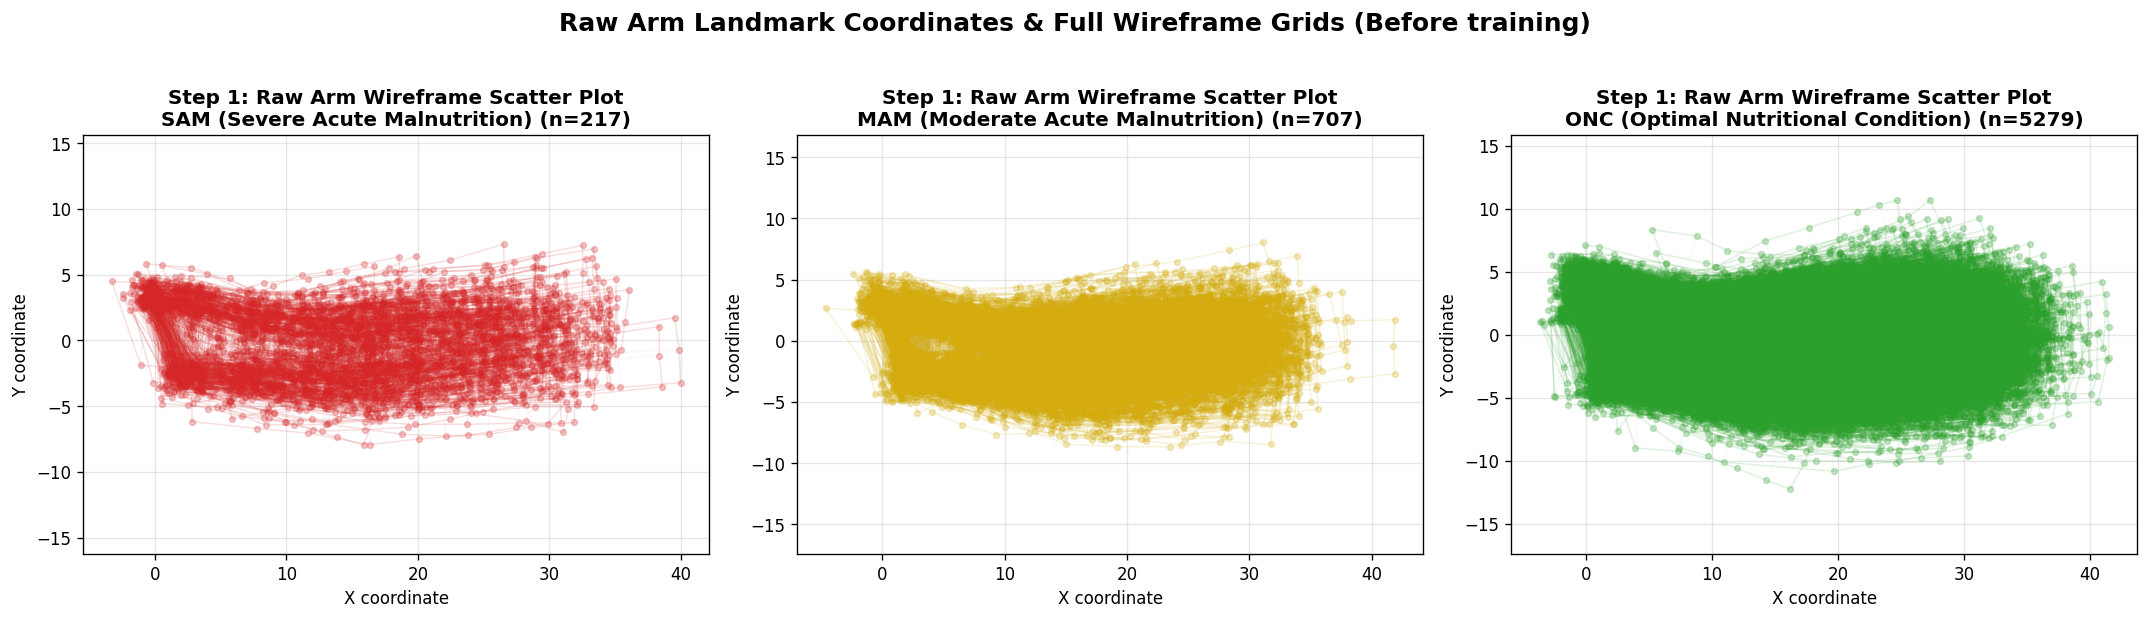

In [4]:
# Raw Landmark Scatter Plot & Arm Wireframes (Before Training)
landmark_ids = [lid for lid in range(1, 23) if f'X{lid}' in df.columns]
id_to_idx = {lid: i for i, lid in enumerate(landmark_ids)}
K = len(landmark_ids)

upper_contour_ids = [1, 12, 14, 16, 18, 10, 8, 6, 20]
upper_contour_idx = [id_to_idx[lid] for lid in upper_contour_ids if lid in id_to_idx]
lower_contour_ids = [4, 13, 15, 17, 9, 7, 5, 19]
lower_contour_idx = [id_to_idx[lid] for lid in lower_contour_ids if lid in id_to_idx]
shoulder_edge_idx = [id_to_idx[1], id_to_idx[4]] if (1 in id_to_idx and 4 in id_to_idx) else []
wrist_edge_idx = [id_to_idx[lid] for lid in [20, 3, 19] if lid in id_to_idx]
dashed_cross_ids = [[12, 4], [14, 13], [16, 15], [18, 17], [10, 9], [8, 7], [6, 5]]
dashed_cross_idx = [[id_to_idx[lid] for lid in seg if lid in id_to_idx] for seg in dashed_cross_ids]
midline_idx = [id_to_idx[lid] for lid in [2, 3] if lid in id_to_idx]

def plot_arm_wireframe(ax, shapes, color='black', alpha_solid=0.8, alpha_dashed=0.4, 
                       lw_solid=1.5, lw_dashed=1.0, alpha_scatter=0.6, s=20, 
                       label=None, show_labels=True, monochrome=True):
    shapes_arr = np.asarray(shapes)
    if shapes_arr.ndim == 2:
        shapes_arr = shapes_arr[np.newaxis, :, :]
    elif shapes_arr.ndim == 3:
        if shapes_arr.shape[1] == 2 and shapes_arr.shape[0] != 2:
            shapes_arr = np.transpose(shapes_arr, (2, 0, 1))

    N_samples = shapes_arr.shape[0]
    c_upper = color if monochrome else 'red'
    c_lower = color if monochrome else 'blue'
    c_shoulder = color if monochrome else 'purple'
    c_wrist = color if monochrome else 'green'
    c_cross = color if monochrome else 'gray'
    c_midline = color if monochrome else 'gold'

    if alpha_scatter > 0 and s > 0:
        all_x = shapes_arr[:, :, 0].flatten()
        all_y = shapes_arr[:, :, 1].flatten()
        ax.scatter(all_x, all_y, color=color, alpha=alpha_scatter, s=s, zorder=3, label=label if label else None)

    for i in range(N_samples):
        sh = shapes_arr[i]
        if upper_contour_idx:
            ax.plot(sh[upper_contour_idx, 0], sh[upper_contour_idx, 1], color=c_upper, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        if lower_contour_idx:
            ax.plot(sh[lower_contour_idx, 0], sh[lower_contour_idx, 1], color=c_lower, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        if shoulder_edge_idx:
            ax.plot(sh[shoulder_edge_idx, 0], sh[shoulder_edge_idx, 1], color=c_shoulder, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        if wrist_edge_idx:
            ax.plot(sh[wrist_edge_idx, 0], sh[wrist_edge_idx, 1], color=c_wrist, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        for seg in dashed_cross_idx:
            ax.plot(sh[seg, 0], sh[seg, 1], color=c_cross, 
                    alpha=alpha_dashed, linewidth=lw_dashed, linestyle='--', zorder=4)
        if len(midline_idx) >= 2:
            ax.plot(sh[midline_idx, 0], sh[midline_idx, 1], color=c_midline, 
                    alpha=alpha_solid * 0.8, linewidth=lw_dashed, linestyle=':', zorder=4)

# Extract raw 2D landmark coordinates matrix M (N, K, 2)
shapes_raw = np.zeros((len(df), K, 2))
for i in range(len(df)):
    for lid_idx, lid in enumerate(landmark_ids):
        shapes_raw[i, lid_idx, 0] = df.iloc[i][f'X{lid}']
        shapes_raw[i, lid_idx, 1] = df.iloc[i][f'Y{lid}']

true_class = df['Class_Type'].values
class_colors = {'sam': '#d62728', 'mam': '#d4ac0d', 'onc': '#2ca02c'}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
classes = ['sam', 'mam', 'onc']
titles = ['SAM (Severe Acute Malnutrition)', 'MAM (Moderate Acute Malnutrition)', 'ONC (Optimal Nutritional Condition)']

for ax, cls, title in zip(axes, classes, titles):
    indices = np.where(true_class == cls)[0]
    plot_arm_wireframe(ax, shapes_raw[indices], color=class_colors[cls], 
                       alpha_solid=0.15, alpha_dashed=0.08, lw_solid=0.9, lw_dashed=0.6, alpha_scatter=0.25, s=12, show_labels=False)
    ax.set_title(f'Step 1: Raw Arm Wireframe Scatter Plot\n{title} (n={len(indices)})', fontsize=12, fontweight='bold')
    ax.set_xlabel('X coordinate')
    ax.set_ylabel('Y coordinate')
    ax.grid(True, alpha=0.3)
    ax.axis('equal')

plt.suptitle('Raw Arm Landmark Coordinates & Full Wireframe Grids (Before training)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [5]:
# Stratified 5-Fold Cross Validation & Multi-Class Metrics Tracking with Borderline-SMOTE
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

class_names = ['ONC', 'MAM', 'SAM']
per_class_recalls = {cls: [] for cls in class_names}
per_class_precisions = {cls: [] for cls in class_names}
per_class_f1s = {cls: [] for cls in class_names}

macro_f1s, balanced_accs = [], []
cm_total = np.zeros((3, 3), dtype=int)

print(f"🚀 Running 5-Fold Stratified Cross-Validation (Exp 6: Full Data with Borderline-SMOTE (Training Fold Only))...\n")

for fold, (train_idx, test_idx) in enumerate(cv.split(X_exp, y_exp), 1):
    X_tr, y_tr = X_exp[train_idx], y_exp[train_idx]
    X_te, y_te = X_exp[test_idx], y_exp[test_idx]

    # Apply Borderline-SMOTE oversampling strictly INSIDE training fold to prevent data leakage
    bsmote = BorderlineSMOTE(random_state=RANDOM_STATE, k_neighbors=3)
    X_res, y_res = bsmote.fit_resample(X_tr, y_tr)

    model = XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', random_state=RANDOM_STATE, n_estimators=100, learning_rate=0.1, max_depth=4)
    model.fit(X_res, y_res)

    y_pred = model.predict(X_te)

    # Per-class metrics
    rec_all = recall_score(y_te, y_pred, labels=[0, 1, 2], average=None)
    prec_all = precision_score(y_te, y_pred, labels=[0, 1, 2], average=None, zero_division=0)
    f1_all = f1_score(y_te, y_pred, labels=[0, 1, 2], average=None)

    for i, cls in enumerate(class_names):
        per_class_recalls[cls].append(rec_all[i])
        per_class_precisions[cls].append(prec_all[i])
        per_class_f1s[cls].append(f1_all[i])

    m_f1 = f1_score(y_te, y_pred, average='macro')
    b_acc = balanced_accuracy_score(y_te, y_pred)
    macro_f1s.append(m_f1)
    balanced_accs.append(b_acc)
    cm_total += confusion_matrix(y_te, y_pred, labels=[0, 1, 2])

    print(f"Fold {fold}: SAM Rec={rec_all[2]:.4f} Prec={prec_all[2]:.4f} | MAM Rec={rec_all[1]:.4f} Prec={prec_all[1]:.4f} | ONC Rec={rec_all[0]:.4f} Prec={prec_all[0]:.4f} | Macro F1={m_f1:.4f}")


🚀 Running 5-Fold Stratified Cross-Validation (Exp 6: Full Data with Borderline-SMOTE (Training Fold Only))...

Fold 1: SAM Rec=0.3953 Prec=0.1954 | MAM Rec=0.6197 Prec=0.4074 | ONC Rec=0.8456 Prec=0.9520 | Macro F1=0.5496
Fold 2: SAM Rec=0.6364 Prec=0.3011 | MAM Rec=0.6831 Prec=0.4025 | ONC Rec=0.8209 Prec=0.9548 | Macro F1=0.5994
Fold 3: SAM Rec=0.4091 Prec=0.2535 | MAM Rec=0.5816 Prec=0.3923 | ONC Rec=0.8485 Prec=0.9324 | Macro F1=0.5567
Fold 4: SAM Rec=0.4651 Prec=0.2532 | MAM Rec=0.6950 Prec=0.3813 | ONC Rec=0.8201 Prec=0.9580 | Macro F1=0.5680
Fold 5: SAM Rec=0.5116 Prec=0.2716 | MAM Rec=0.5674 Prec=0.3960 | ONC Rec=0.8504 Prec=0.9383 | Macro F1=0.5712


In [6]:
print("=================================================================")
print("🏆 SUMMARY RESULTS: EXP 6 - FULL DATA WITH BORDERLINE-SMOTE (TRAINING FOLD ONLY)")
print("=================================================================")

df_metrics_summary = pd.DataFrame({
    'Class': class_names,
    'Recall (Mean)': [np.mean(per_class_recalls[c]) for c in class_names],
    'Recall (Std)': [np.std(per_class_recalls[c]) for c in class_names],
    'Precision (Mean)': [np.mean(per_class_precisions[c]) for c in class_names],
    'Precision (Std)': [np.std(per_class_precisions[c]) for c in class_names],
    'F1-Score (Mean)': [np.mean(per_class_f1s[c]) for c in class_names],
    'F1-Score (Std)': [np.std(per_class_f1s[c]) for c in class_names]
})

print(df_metrics_summary.to_string(index=False))

print("-----------------------------------------------------------------")
print(f"📈 Overall Macro F1-Score   : {np.mean(macro_f1s):.4f} ± {np.std(macro_f1s):.4f}")
print(f"⚖️  Overall Balanced Accuracy: {np.mean(balanced_accs):.4f} ± {np.std(balanced_accs):.4f}")
print("=================================================================")


🏆 SUMMARY RESULTS: EXP 6 - FULL DATA WITH BORDERLINE-SMOTE (TRAINING FOLD ONLY)
Class  Recall (Mean)  Recall (Std)  Precision (Mean)  Precision (Std)  F1-Score (Mean)  F1-Score (Std)
  ONC       0.837087      0.013658          0.947099         0.009953         0.888556        0.004928
  MAM       0.629358      0.051809          0.395921         0.008955         0.485131        0.015336
  SAM       0.483510      0.086953          0.254954         0.034514         0.333210        0.048472
-----------------------------------------------------------------
📈 Overall Macro F1-Score   : 0.5690 ± 0.0171
⚖️  Overall Balanced Accuracy: 0.6500 ± 0.0358


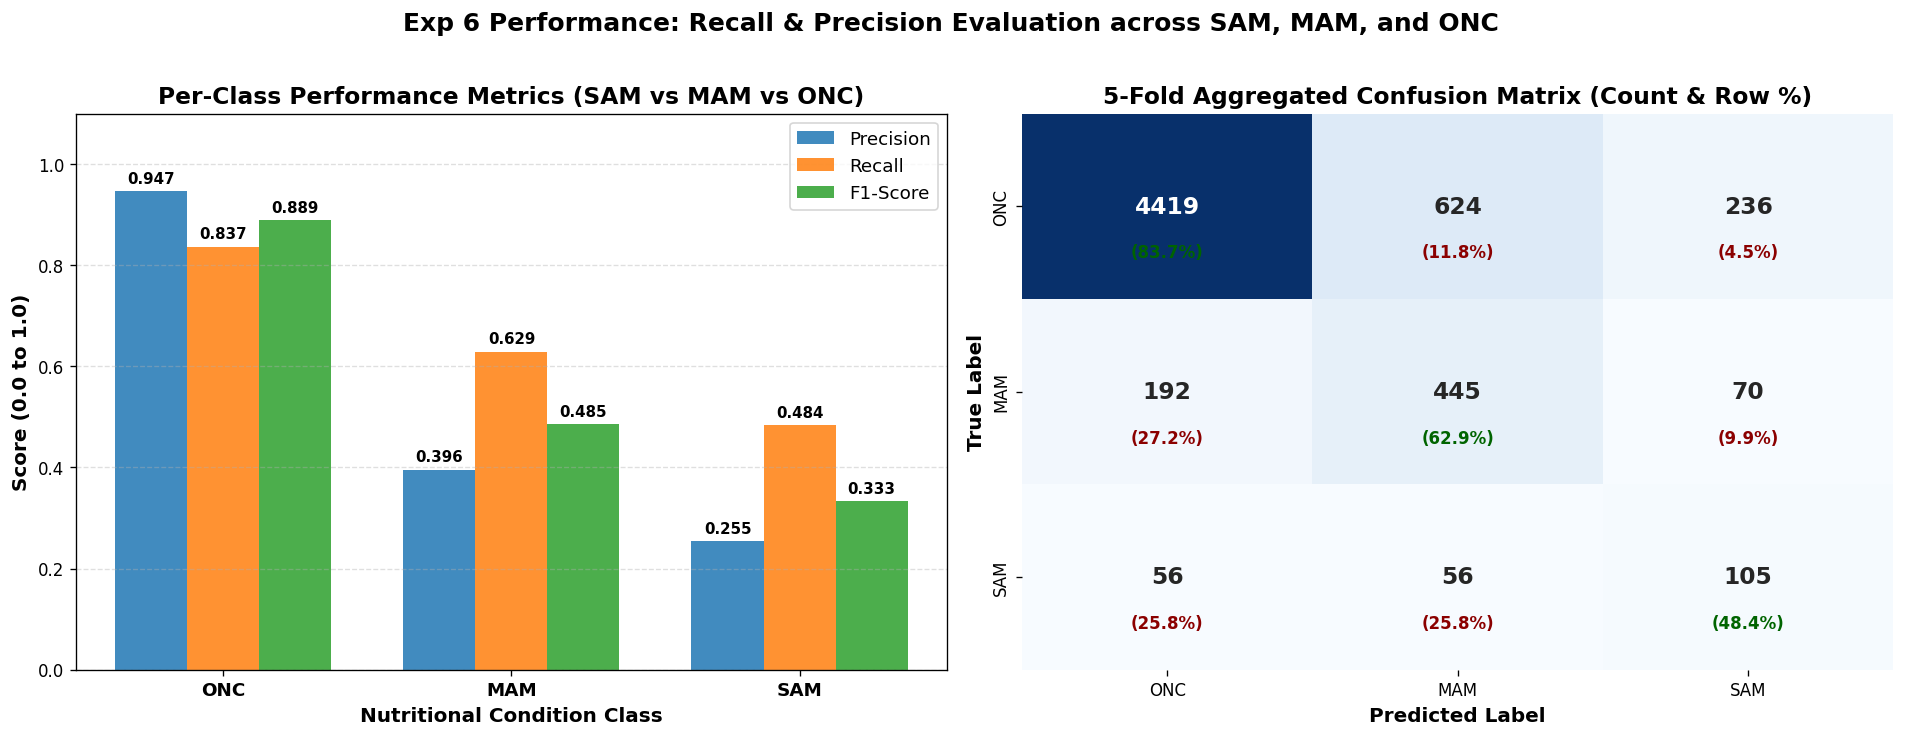

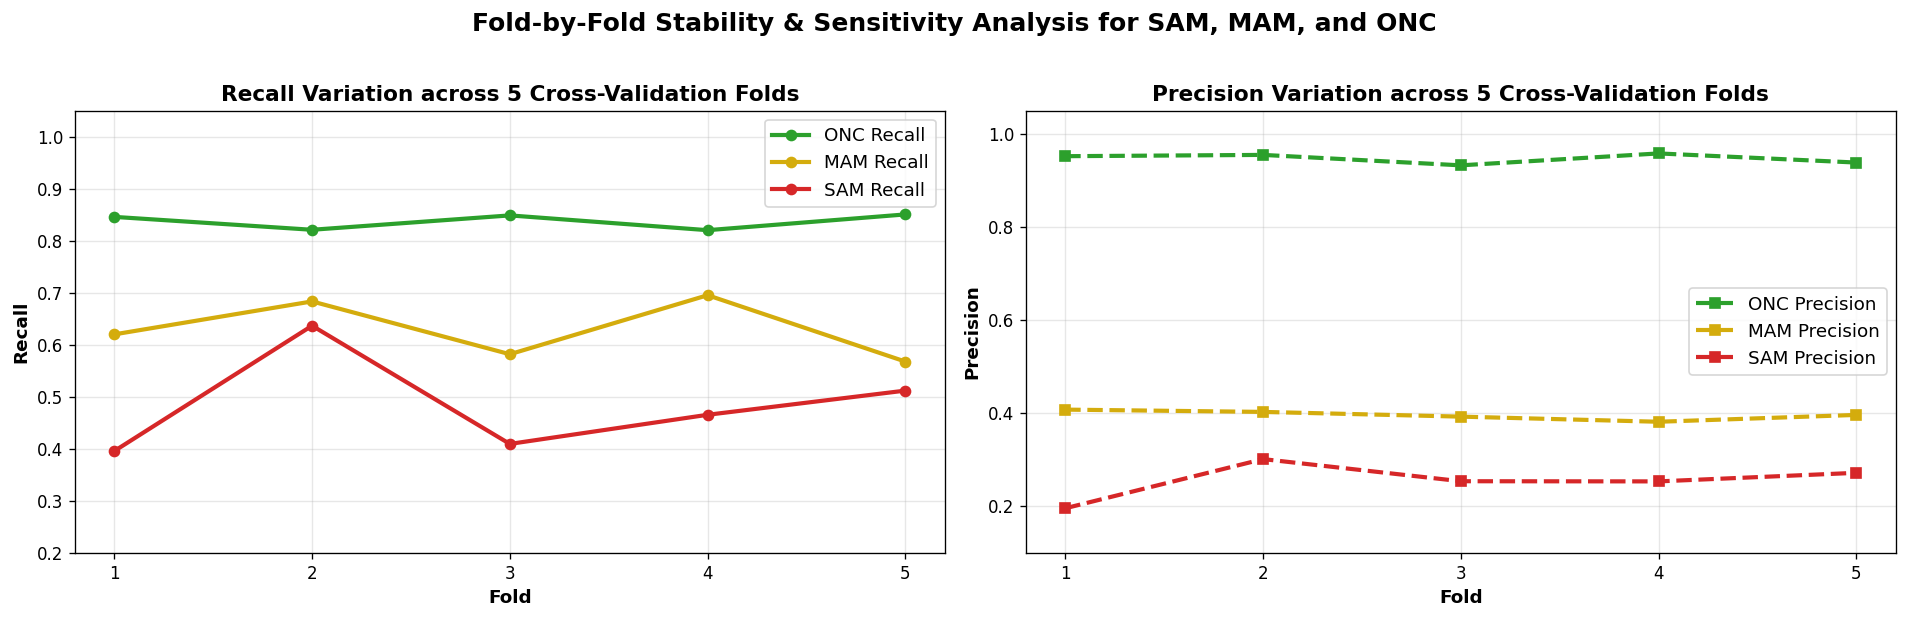

In [7]:
# Precision, Recall & F1-Score Comparison Plot Across All Classes (SAM, MAM, ONC)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Grouped Bar Chart for Precision, Recall, and F1-Score
x = np.arange(len(class_names))
width = 0.25

rects1 = axes[0].bar(x - width, df_metrics_summary['Precision (Mean)'], width, label='Precision', color='#1f77b4', alpha=0.85)
rects2 = axes[0].bar(x, df_metrics_summary['Recall (Mean)'], width, label='Recall', color='#ff7f0e', alpha=0.85)
rects3 = axes[0].bar(x + width, df_metrics_summary['F1-Score (Mean)'], width, label='F1-Score', color='#2ca02c', alpha=0.85)

axes[0].set_title('Per-Class Performance Metrics (SAM vs MAM vs ONC)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Nutritional Condition Class', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Score (0.0 to 1.0)', fontsize=12, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(class_names, fontsize=11, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].set_ylim(0, 1.1)
axes[0].grid(True, linestyle='--', alpha=0.4, axis='y')

# Add values above bars
def autolabel(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects1, axes[0])
autolabel(rects2, axes[0])
autolabel(rects3, axes[0])

# Plot 2: Confusion Matrix Heatmap
cm_norm = cm_total.astype('float') / cm_total.sum(axis=1)[:, np.newaxis]

sns.heatmap(cm_total, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names, cbar=False,
            annot_kws={'size': 14, 'weight': 'bold'})

for i in range(len(class_names)):
    for j in range(len(class_names)):
        axes[1].text(j + 0.5, i + 0.75, f"({cm_norm[i, j]*100:.1f}%)",
                     ha='center', va='center', color='darkred' if i != j else 'darkgreen',
                     fontsize=10, fontweight='bold')

axes[1].set_title('5-Fold Aggregated Confusion Matrix (Count & Row %)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
axes[1].set_ylabel('True Label', fontsize=12, fontweight='bold')

plt.suptitle('Exp 6 Performance: Recall & Precision Evaluation across SAM, MAM, and ONC', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Plot 3: Fold-by-Fold Recall & Precision Breakdown
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
folds = np.arange(1, 6)

for cls, color in zip(class_names, ['#2ca02c', '#d4ac0d', '#d62728']):
    axes[0].plot(folds, per_class_recalls[cls], marker='o', linewidth=2.5, label=f'{cls} Recall', color=color)
    axes[1].plot(folds, per_class_precisions[cls], marker='s', linestyle='--', linewidth=2.5, label=f'{cls} Precision', color=color)

axes[0].set_title('Recall Variation across 5 Cross-Validation Folds', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Fold', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Recall', fontsize=11, fontweight='bold')
axes[0].set_xticks(folds)
axes[0].set_ylim(0.2, 1.05)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=11)

axes[1].set_title('Precision Variation across 5 Cross-Validation Folds', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Fold', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Precision', fontsize=11, fontweight='bold')
axes[1].set_xticks(folds)
axes[1].set_ylim(0.1, 1.05)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=11)

plt.suptitle('Fold-by-Fold Stability & Sensitivity Analysis for SAM, MAM, and ONC', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
